In [ ]:
import torch
import torch.nn as nn
import torch.fft
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

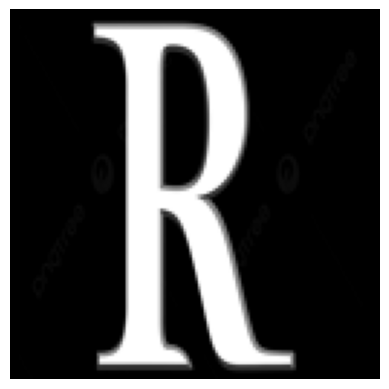

In [ ]:
img = Image.open("x.png").convert("L")
img = img.resize((128,128))

image = np.array(img, dtype=np.float32)
image = image / 255.0

target = torch.tensor(image).unsqueeze(0).unsqueeze(0)

plt.imshow(image, cmap="gray")
plt.axis("off")
plt.show()

In [ ]:
target_amp = torch.sqrt(target)

In [ ]:
def propagate(field, z):

    N = 128
    wavelength = 532e-9
    pixel = 10e-6

    fx = torch.fft.fftfreq(N, pixel)
    fy = torch.fft.fftfreq(N, pixel)

    FX, FY = torch.meshgrid(fx, fy, indexing="xy")

    k = 2 * torch.pi / wavelength

    H = torch.exp(
        1j * k * z *
        torch.sqrt(
            torch.clamp(
                1 - (wavelength*FX)**2 -
                (wavelength*FY)**2,
                min=0
            )
        )
    )

    return torch.fft.ifft2(
        torch.fft.fft2(field) * H
    )

In [ ]:
phase = torch.zeros_like(target_amp, requires_grad=True)

optimizer = torch.optim.Adam([phase], lr=0.05)

for i in range(2000):

    optimizer.zero_grad()

    hologram = torch.exp(1j * phase)

    reconstruction = propagate(hologram, 0.2)

    reconstruction = torch.abs(reconstruction)

    reconstruction = reconstruction / reconstruction.max()

    loss = torch.mean((reconstruction - target_amp) ** 2)

    loss.backward()
    optimizer.step()

    if i % 200 == 0:
        print(i, loss.item())

best_phase = torch.angle(torch.exp(1j * phase)).detach()

0 0.7536340355873108
200 0.1362706869840622
400 0.08979827910661697
600 0.05792153626680374
800 0.03932998329401016
1000 0.036921948194503784
1200 0.03327876329421997
1400 0.035453859716653824
1600 0.035869523882865906
1800 0.037508461624383926


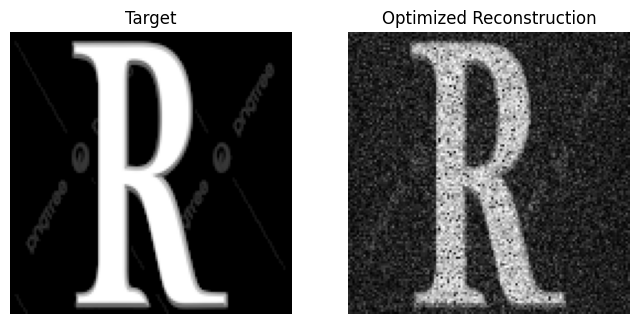

In [ ]:
hologram = torch.exp(1j * best_phase)

reconstruction = torch.abs(
    propagate(hologram, 0.2)
).detach()

reconstruction = reconstruction / reconstruction.max()

plt.figure(figsize=(8,4))

plt.subplot(1,2,1)
plt.imshow(target_amp[0,0], cmap="gray")
plt.title("Target")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(reconstruction[0,0], cmap="gray")
plt.title("Optimized Reconstruction")
plt.axis("off")

plt.show()

In [ ]:
class NeuralHologram(nn.Module):

    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.Conv2d(3, 64, 3, padding=1),
            nn.ReLU(),

            nn.Conv2d(64, 64, 3, padding=1),
            nn.ReLU(),

            nn.Conv2d(64, 64, 3, padding=1),
            nn.ReLU(),

            nn.Conv2d(64, 64, 3, padding=1),
            nn.ReLU(),

            nn.Conv2d(64, 1, 3, padding=1)
        )

    def forward(self, x):
        return torch.pi * torch.tanh(self.net(x))

In [ ]:
N = 128

x = torch.linspace(-1, 1, N)
y = torch.linspace(-1, 1, N)

X, Y = torch.meshgrid(x, y, indexing="xy")

X = X.unsqueeze(0).unsqueeze(0)
Y = Y.unsqueeze(0).unsqueeze(0)

network_input = torch.cat(
    [target_amp, X, Y],
    dim=1
)

print(network_input.shape)

torch.Size([1, 3, 128, 128])


In [ ]:
model = NeuralHologram()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

In [ ]:
for i in range(5000):

    optimizer.zero_grad()

    predicted_phase = model(network_input)

    loss = torch.mean(
        1 - torch.cos(predicted_phase - best_phase)
    )

    loss.backward()

    optimizer.step()

    if i % 500 == 0:
        print(i, loss.item())

0 0.7173753976821899
500 0.44342830777168274
1000 0.41897809505462646
1500 0.39489370584487915
2000 0.3904500901699066
2500 0.3623807430267334
3000 0.36437591910362244
3500 0.34417644143104553
4000 0.3285154402256012
4500 0.3266928195953369
